# MerkaDo — Enhanced Exploratory Data Analysis (CRISP-DM Phase 2)
**Group 5 · Introduction to Data Science** — Delos Santos, Rabano, Bautista

This notebook runs the full MerkaDo EDA on **any sales log with the same basic columns**:

* **Weeks 1–3 (now):** the Aling Nena Q1 2026 proxy CSV (MB Regal Solutions). Results here are for **testing the code only**.
* **Week 3 onward:** the partner sari-sari store log (Sta. Mesa, Manila). Change `DATA_PATH` (and `COLUMN_MAP` if your headers differ), then *Run All*.

| Step | What it checks |
|---|---|
| 1 | Load and standardize columns; product-name standardization (aliases + fuzzy matching) and pack/tingi conversion |
| 2 | Data quality: missing values, duplicates, closed vs. unlogged days, outliers, prices vs. cost and DTI SRP |
| 3 | Sales overview and payment mix (cash / GCash / utang) |
| 4 | ABC (Pareto) analysis |
| 5 | Demand-type classification (ADI / CV²) |
| 6 | Time patterns: weekday, product × weekday heatmap, ACF, STL, payday/weekend/rain regression, time of day |
| 7 | Basket EDA before Apriori: basket sizes, single-item share, co-occurrence, `min_support`, rules with minimum count and Fisher's exact test |
| 8 | Stockouts and estimated lost demand |
| 9 | Week-over-week batch summary |
| 10 | Rolling-origin forecast check: 1-day and 7-day-total error, bias and MASE, with Croston (SBA) |
| 11 | Next-7-day restock suggestion with an 80% range |
| 12 | Automatic summary and saved outputs |

Optional columns are detected automatically: `Trans_ID`, `Time`, `Category`, `UnitPrice`, `UnitCost`, `PaymentType`, `Stockout_Flag`, `Is_Rainy`, `Pack_Multiplier` or `Unit`, `Store_Open`. Steps that need a missing column are skipped and the notebook says why.

## 0. Configuration

In [1]:
import os, re, math, difflib, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.formula.api as smf
from statsmodels.tsa.stattools import acf
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from sklearn.linear_model import LinearRegression
from mlxtend.frequent_patterns import apriori, association_rules

warnings.filterwarnings('ignore')
pd.set_option('display.width', 160); pd.set_option('display.max_columns', 30)
sns.set_theme(style='whitegrid', font_scale=0.9)

# ---- Change these for the partner store log ------------------------------
DATA_PATH     = os.environ.get('MERKADO_DATA',  'data/aling-nena-sales-q1-2026.csv')
DATASET_LABEL = os.environ.get('MERKADO_LABEL', 'Aling Nena Q1 2026 (online PH proxy, code testing only)')
OUT = Path(os.environ.get('MERKADO_OUT', 'outputs')); OUT.mkdir(parents=True, exist_ok=True)
# Supabase: the connection-pooler string for the read-only role merkado_reader (env var or Colab Secrets). Never hard-code it.
DB_URL = os.environ.get('MERKADO_DB_URL', '')
BACKUP = True             # save a CSV of every reporting view to OUT/backup/<today>/ when reading the database

# Map your log's column headers to the names used in this notebook
COLUMN_MAP = {
    'Standardized SKU': 'Product', 'Item': 'Product',
    'Qty Sold': 'Qty', 'Quantity': 'Qty',
    'Trans ID': 'Trans_ID', 'Transaction_ID': 'Trans_ID',
    'Payment Type': 'PaymentType', 'Unit Price': 'UnitPrice', 'Unit Cost': 'UnitCost',
    'Stockout': 'Stockout_Flag', 'is_rainy': 'Is_Rainy', 'Pack multiplier': 'Pack_Multiplier',
    'Pack size sold': 'Unit', 'Unit sold': 'Unit', 'Store open': 'Store_Open',
}

PAYDAY_DAYS  = {14, 15, 16, 29, 30, 31, 1}   # kinsenas / katapusan window
HOLDOUT_DAYS = 28                            # rolling-origin test window (shrinks automatically for short logs)
TOP_N        = 6                             # products to forecast individually

# DTI BNPC SRP Bulletin, effective 11 May 2026 (per selling unit). Only include exact brand + size matches.
SRP_PER_UNIT = {
    'Pandesal': 27.25 / 10,          # Pinoy Pandesal 10 pcs / 250 g
    'Lucky Me Beef Noodles': 9.00,   # Lucky Me! Instant Mami Beef 55 g (assumed 55 g pack)
    'Kopiko 3-in-1': 8.50,           # Kopiko Black 30 g (assumed same sachet)
}
ADD_MOCK_STOCKOUTS = True   # only used if the file has no Stockout_Flag column (code testing)

# Product-name standardization: lower-case aliases -> standard name
ALIASES = {'kopiko blk': 'Kopiko Black Twin', 'kopiko black': 'Kopiko Black Twin',
           'pandesal pc': 'Pandesal', 'lucky me canton': 'Lucky Me Pancit Canton', 'kopiko 3in1': 'Kopiko 3-in-1'}
CANONICAL_PRODUCTS = []   # optional master list; empty = learn standard names from the most common spellings
FUZZY_CUTOFF = 0.88       # similarity needed to auto-merge a misspelling (always listed for checking)
# Tingi / wholesale conversion: (product, unit sold) -> base units
PACK_TABLE = {('Kopiko Black Twin', 'banig'): 12, ('Nescafe Original Stick', 'pack'): 48,
              ('Pandesal', 'bag'): 10, ('Shampoo Sachet', 'banig'): 12}

MIN_SELLING_DAYS = 8      # outlier rule only for products with at least this many selling days
MIN_PAIR_BASKETS = 5      # a basket rule must appear in at least this many baskets
CROSTON_ALPHA = 0.1
INTERVAL = (0.10, 0.90)   # 80% range for the restock suggestion
print('Dataset:', DATASET_LABEL, '|', DATA_PATH)

Dataset: Aling Nena Q1 2026 (online PH proxy, code testing only) | data/aling-nena-sales-q1-2026.csv


In [2]:
# Read the Supabase database when DB_URL is set; otherwise (or if it cannot be reached) use the CSV at DATA_PATH
from merkado_db import events_to_log, from_db
raw, STOCK = None, {}
if DB_URL:
    try:
        raw, STOCK = from_db(DB_URL, out=OUT, backup=BACKUP)
        print(f'Read {len(raw):,} rows from the database | stock counts for {len(STOCK)} products'
              + (f' | backup saved to {OUT / "backup"}' if BACKUP else ''))
    except Exception as e:
        print('Could not reach the database (the Supabase project may be paused: open the dashboard and click Restore). '
              f'Falling back to DATA_PATH = {DATA_PATH}')
        print(f'  ({type(e).__name__}: {str(e).splitlines()[0] if str(e) else ""})')
        raw, STOCK = None, {}


## 1. Load and standardize

In [3]:
if raw is None: raw = pd.read_csv(DATA_PATH, encoding='utf-8-sig')
df = raw.rename(columns=COLUMN_MAP).copy()
missing_req = {'Date', 'Product', 'Qty'} - set(df.columns)
assert not missing_req, f'Missing required columns: {missing_req}'

df['Date'] = pd.to_datetime(df['Date'])
HAS = {c: c in df for c in ['Trans_ID', 'Time', 'Category', 'UnitPrice', 'UnitCost', 'PaymentType',
                              'Stockout_Flag', 'Is_Rainy', 'Pack_Multiplier', 'Unit', 'Store_Open']}
# Days the store was closed (Store_Open = 0) are kept separate from days that were simply not logged
CLOSED = set()
if HAS['Store_Open']:
    CLOSED = set(df.loc[df['Store_Open'].eq(0), 'Date'])
    df = df[df['Store_Open'].ne(0)].copy()
if HAS['UnitPrice']: df['Sales'] = df['Qty'] * df['UnitPrice']
if HAS['UnitPrice'] and HAS['UnitCost']: df['Profit'] = df['Qty'] * (df['UnitPrice'] - df['UnitCost'])

days = pd.date_range(df['Date'].min(), df['Date'].max(), freq='D')
N_DAYS = len(days)
print(f'{len(df):,} rows x {raw.shape[1]} columns | {df.Date.min().date()} to {df.Date.max().date()} '
      f'({N_DAYS} days) | {df.Product.nunique()} raw product names')
print('Optional columns found:', [k for k, v in HAS.items() if v] or 'none')
print('Missing optional columns:', [k for k, v in HAS.items() if not v] or 'none')
df.head()

494 rows x 7 columns | 2026-01-01 to 2026-03-31 (90 days) | 22 raw product names
Optional columns found: ['Category', 'UnitPrice', 'UnitCost', 'PaymentType']
Missing optional columns: ['Trans_ID', 'Time', 'Stockout_Flag', 'Is_Rainy', 'Pack_Multiplier', 'Unit', 'Store_Open']


,Date,Product,Category,Qty,UnitPrice,UnitCost,PaymentType,Sales,Profit
0,2026-01-01,Cellphone Load 50,Load,1,50,47,Cash,50,3
1,2026-01-01,Lucky Me Pancit Canton,Noodles,1,15,12,GCash,15,3
2,2026-01-01,Sky Flakes,Snacks,2,8,6,GCash,16,4
3,2026-01-02,Cellphone Load 50,Load,1,50,47,Cash,50,3
4,2026-01-02,Palmolive Soap,Household,3,30,24,Cash,90,18


### 1b. Product-name standardization and pack / tingi conversion
Free-text names are matched in this order: alias table → exact match after lower-casing and removing punctuation → fuzzy match (`difflib`, similarity ≥ `FUZZY_CUTOFF`). Fuzzy and unmatched names are listed so a group member can confirm them and add them to `ALIASES`.

In [4]:
def norm(s): return re.sub(r'[^a-z0-9]+', ' ', str(s).lower()).strip()
def close_match(n, candidates):
    # never merge names whose numbers differ (e.g. Load 50 vs. Load 100, 155g vs. 425g)
    same_num = [c for c in candidates if re.findall(r'\d+', c) == re.findall(r'\d+', n)]
    m = difflib.get_close_matches(n, same_num, n=1, cutoff=FUZZY_CUTOFF)
    return m[0] if m else None
df['Raw_Product'] = df['Product'].astype(str)
counts = df['Raw_Product'].map(norm).value_counts()
alias_n = {norm(k): v for k, v in ALIASES.items()}
if CANONICAL_PRODUCTS:
    canon = {norm(c): c for c in CANONICAL_PRODUCTS}
else:   # learn standard names from names seen at least 3 times, most frequent first
    spelling = {n: g.str.strip().value_counts().index[0] for n, g in df.groupby(df['Raw_Product'].map(norm))['Raw_Product']}
    canon = {}
    for n in counts.index:
        if counts[n] < 3 or n in alias_n: continue
        if close_match(n, list(canon)) is None:
            canon[n] = spelling[n]   # a frequent misspelling of an existing name is left to the fuzzy step
canon.update({norm(v): v for v in alias_n.values() if norm(v) not in canon})

def standardize(raw):
    n = norm(raw)
    if n in alias_n: return alias_n[n], 'alias'
    if n in canon: return canon[n], 'exact'
    m = close_match(n, list(canon))
    if m: return canon[m], 'fuzzy (check)'
    return str(raw).strip(), 'unmatched (check)'

uniq = df['Raw_Product'].drop_duplicates()
mapping = pd.DataFrame([(r, *standardize(r)) for r in uniq], columns=['Raw name', 'Standard name', 'Method'])
mapping['Rows'] = mapping['Raw name'].map(df['Raw_Product'].value_counts())
df['Product'] = df['Raw_Product'].map(dict(zip(mapping['Raw name'], mapping['Standard name'])))
mapping.to_csv(OUT / 'name_mapping.csv', index=False)
print(f"{len(uniq)} raw names -> {df.Product.nunique()} standard products |", mapping.Method.value_counts().to_dict())

# Pack / tingi conversion into base units
if HAS['Pack_Multiplier']:
    if HAS['Unit']:   # rows from the database keep their multiplier unless PACK_TABLE has a manual entry
        pt = {(p, u.lower()): m for (p, u), m in PACK_TABLE.items()}
        df['Pack_Multiplier'] = [pt.get((p, str(u).lower().strip()), m) for p, u, m in zip(df['Product'], df['Unit'], df['Pack_Multiplier'])]
    df['Base_Qty'] = df['Qty'] * df['Pack_Multiplier']
elif HAS['Unit']:
    pt = {(p, u.lower()): m for (p, u), m in PACK_TABLE.items()}
    df['Pack_Multiplier'] = [pt.get((p, str(u).lower().strip()), 1) for p, u in zip(df['Product'], df['Unit'])]
    df['Base_Qty'] = df['Qty'] * df['Pack_Multiplier']
    print('Rows converted from packs to base units:', int((df.Pack_Multiplier > 1).sum()))
else:
    df['Base_Qty'] = df['Qty']
mapping[mapping.Method != 'exact'].sort_values('Method')

22 raw names -> 22 standard products | {'exact': 22}


,Raw name,Standard name,Method,Rows


## 2. Data quality checks

In [5]:
qc = {
    'Rows': len(df),
    'Missing values (all columns)': int(df.isna().sum().sum()),
    'Calendar days in range': N_DAYS,
    'Days marked closed (Store_Open = 0)': len(CLOSED),
    'Days with no records and not marked closed': None,
    'Exact duplicate rows (extra copies)': int(df.duplicated().sum()),
}
UNLOGGED = [d for d in days if d not in set(df['Date']) and d not in CLOSED]
qc['Days with no records and not marked closed'] = len(UNLOGGED)
if HAS['Trans_ID']:
    # Same Trans_ID + same item line twice = double entry -> remove
    df = df.drop_duplicates().reset_index(drop=True)
    qc['Duplicate rule'] = 'Trans_ID present: exact duplicates treated as double entry and removed'
else:
    df['Dup_Flag'] = df.duplicated(keep=False).astype(int)
    qc['Duplicate rule'] = 'No Trans_ID: duplicates flagged (Dup_Flag) but kept, since they may be two real sales'
pd.Series(qc, name='value').to_frame()

,value
Rows,494
Missing values (all columns),0
Calendar days in range,90
Days marked closed (Store_Open = 0),0
Days with no records and not marked closed,0
Exact duplicate rows (extra copies),5
Duplicate rule,No Trans_ID: duplicates flagged (Dup_Flag) but...


In [6]:
# Duplicate rows (for manual checking against the paper log)
dup_view = raw[raw.duplicated(keep=False)].sort_values(list(raw.columns[:2]))
dup_view

,Date,Product,Category,Qty,UnitPrice,UnitCost,PaymentType
60,2026-01-13,Rice (kilo),Staples,1,55,50,Cash
61,2026-01-13,Rice (kilo),Staples,1,55,50,Cash
115,2026-01-25,Cellphone Load 50,Load,1,50,47,Cash
120,2026-01-25,Cellphone Load 50,Load,1,50,47,Cash
149,2026-01-30,Coke Mismo,Beverages,4,20,16,Cash
153,2026-01-30,Coke Mismo,Beverages,4,20,16,Cash
231,2026-02-14,Sugar (kilo),Staples,3,70,64,Utang
235,2026-02-14,Sugar (kilo),Staples,3,70,64,Utang
318,2026-02-28,Cooking Oil Pouch,Staples,3,25,21,Cash
321,2026-02-28,Cooking Oil Pouch,Staples,3,25,21,Cash


In [7]:
# Daily units per product (0 = no recorded sale that day)
daily = (df.groupby(['Date', 'Product'])['Base_Qty'].sum()
           .unstack(fill_value=0).reindex(days, fill_value=0))
if UNLOGGED:   # forgotten days: fill with the same-weekday average (flagged), closed days stay 0
    wd = daily.drop(index=UNLOGGED + sorted(CLOSED)).groupby(lambda d: d.dayofweek).mean()
    for d in UNLOGGED: daily.loc[d] = wd.loc[d.dayofweek].round(0)
    print('Unlogged days filled with same-weekday averages:', [d.date() for d in UNLOGGED])

# Outliers: days far above the product's usual selling day (IQR rule on non-zero days)
rows = []
for p in daily:
    nz = daily[p][daily[p] > 0]
    if len(nz) < MIN_SELLING_DAYS: continue
    q1, q3 = nz.quantile([.25, .75]); fence = q3 + 1.5 * (q3 - q1)
    for d, v in nz[nz > fence].items():
        rows.append([d.date(), p, v, nz.median(), round(fence, 1)])
outliers = pd.DataFrame(rows, columns=['Date', 'Product', 'Units', 'Typical day (median)', 'Upper fence'])
n_checked = int(((daily > 0).sum() >= MIN_SELLING_DAYS).sum())
print(f'{len(outliers)} unusually high product-days among {n_checked} products with >= {MIN_SELLING_DAYS} selling days. '
      'Check each one: logging error or real bulk purchase?')
outliers.sort_values('Units', ascending=False).head(10)

18 unusually high product-days among 22 products with >= 8 selling days. Check each one: logging error or real bulk purchase?


,Date,Product,Units,Typical day (median),Upper fence
9,2026-03-21,Kopiko 3-in-1,21,8.0,20.0
8,2026-02-22,Egg,21,11.0,18.5
7,2026-02-04,Egg,19,11.0,18.5
14,2026-02-19,Shampoo Sachet,19,6.0,17.2
15,2026-03-15,Shampoo Sachet,18,6.0,17.2
11,2026-01-04,Nescafe 3-in-1,16,7.0,15.4
12,2026-03-13,Nescafe 3-in-1,16,7.0,15.4
4,2026-01-30,Coke Mismo,14,4.0,7.0
16,2026-01-29,Sky Flakes,14,5.0,13.2
13,2026-01-31,Piattos,10,2.0,8.0


In [8]:
# Price checks: below cost, or above the DTI SRP
if HAS['UnitPrice']:
    agg = {'UnitPrice': ('UnitPrice', 'median')}
    if HAS['UnitCost']: agg['UnitCost'] = ('UnitCost', 'median')
    price = df.groupby('Product').agg(**agg)
    price['DTI_SRP'] = price.index.map(SRP_PER_UNIT).astype(float).round(2)
    if HAS['UnitCost']: price['Below_cost'] = price.UnitPrice < price.UnitCost
    price['Above_SRP'] = price.UnitPrice > price.DTI_SRP
    if HAS['UnitCost']: price['Markup_%'] = ((price.UnitPrice / price.UnitCost - 1) * 100).round(1)
    price_flags = price[price.DTI_SRP.notna() | price.get('Below_cost', False)]
    display(price_flags)
    print('Products priced above DTI SRP:', list(price.index[price.Above_SRP]) or 'none')
else:
    print('Skipped: no UnitPrice column.')

,UnitPrice,UnitCost,DTI_SRP,Below_cost,Above_SRP,Markup_%
Product,,,,,,
Kopiko 3-in-1,8.0,6.0,8.50,False,False,33.3
Lucky Me Beef Noodles,13.0,10.0,9.00,False,True,30.0
Pandesal,3.0,2.0,2.72,False,True,50.0


Products priced above DTI SRP: ['Lucky Me Beef Noodles', 'Pandesal']


## 3. Sales overview and payment mix

In [9]:
overview = {'Total units': int(df.Base_Qty.sum()), 'Units per day': round(df.Base_Qty.sum() / N_DAYS, 1)}
if HAS['UnitPrice']: overview['Total sales (PHP)'] = round(df.Sales.sum(), 2)
if 'Profit' in df:
    overview['Gross profit (PHP)'] = round(df.Profit.sum(), 2)
    overview['Gross margin %'] = round(df.Profit.sum() / df.Sales.sum() * 100, 1)
if HAS['Trans_ID']: overview['Transactions'] = df.Trans_ID.nunique()
display(pd.Series(overview, name='value').to_frame())

if HAS['PaymentType']:
    val = 'Sales' if HAS['UnitPrice'] else 'Base_Qty'
    pay = df.groupby('PaymentType').agg(Rows=('Product', 'size'), Value=(val, 'sum'))
    pay['Share_%'] = (pay.Value / pay.Value.sum() * 100).round(1)
    display(pay)
    ut = (df.assign(is_utang=df.PaymentType.str.lower().eq('utang'))
            .groupby('Product').apply(lambda g: (g[val] * g.is_utang).sum() / g[val].sum() * 100)
            .sort_values(ascending=False).round(1).rename('Utang share of product sales %'))
    display(ut.head(8).to_frame())

,value
Total units,2607.0
Units per day,29.0
Total sales (PHP),32070.0
Gross profit (PHP),6053.0
Gross margin %,18.9


,Rows,Value,Share_%
PaymentType,,,
Cash,239,14266,44.5
GCash,145,9505,29.6
Utang,110,8299,25.9


,Utang share of product sales %
Product,
Rice (kilo),49.2
Sugar (kilo),46.9
Egg,46.1
Cooking Oil Pouch,44.1
Palmolive Soap,33.3
Datu Puti Soy Sauce,32.0
Tasty Bread,30.4
Lucky Me Beef Noodles,26.2


## 4. ABC (Pareto) analysis

Top 20% of products (4 items) = 33.2% of sales
{'A': 14, 'B': 5, 'C': 3}


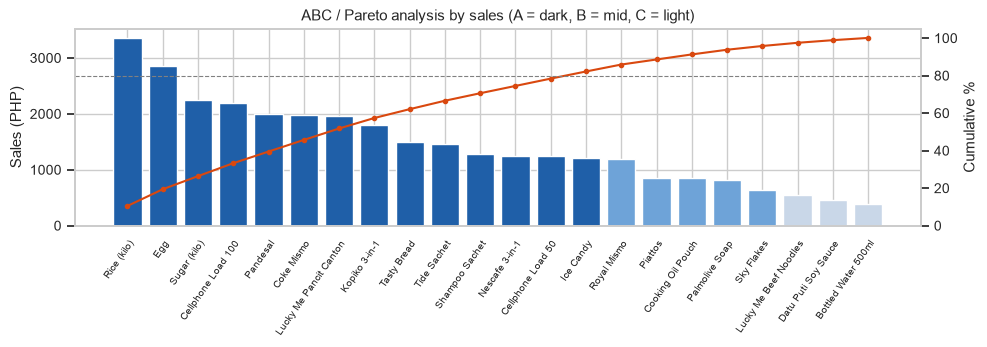

,Units,Sales,Profit,Share_%,Cum_%,ABC
Product,,,,,,
Rice (kilo),61,3355,305,10.5,10.5,A
Egg,317,2853,634,8.9,19.4,A
Sugar (kilo),32,2240,192,7.0,26.4,A
Cellphone Load 100,22,2200,88,6.9,33.3,A
Pandesal,665,1995,665,6.2,39.5,A
Coke Mismo,99,1980,396,6.2,45.7,A
Lucky Me Pancit Canton,131,1965,393,6.1,51.8,A
Kopiko 3-in-1,225,1800,450,5.6,57.4,A
Tasty Bread,23,1495,230,4.7,62.1,A


In [10]:
metric = 'Sales' if HAS['UnitPrice'] else 'Base_Qty'
aggs = {'Units': ('Base_Qty', 'sum')}
if HAS['UnitPrice']: aggs['Sales'] = ('Sales', 'sum')
if 'Profit' in df: aggs['Profit'] = ('Profit', 'sum')
prod = df.groupby('Product').agg(**aggs)
key = 'Sales' if HAS['UnitPrice'] else 'Units'
prod = prod.sort_values(key, ascending=False)
prod['Share_%'] = (prod[key] / prod[key].sum() * 100).round(1)
prod['Cum_%'] = prod['Share_%'].cumsum().round(1)
before = prod['Cum_%'].shift(fill_value=0)
prod['ABC'] = np.where(before < 80, 'A', np.where(before < 95, 'B', 'C'))
top20 = max(1, round(len(prod) * 0.2))
print(f'Top 20% of products ({top20} items) = {prod[key].head(top20).sum() / prod[key].sum() * 100:.1f}% of {key.lower()}')
print(prod.ABC.value_counts().sort_index().to_dict())

fig, ax = plt.subplots(figsize=(10, 3.6))
colors = prod.ABC.map({'A': '#1f5fa8', 'B': '#6ea3d8', 'C': '#c9d7e8'})
ax.bar(prod.index, prod[key], color=colors)
ax.set_ylabel(key + (' (PHP)' if key == 'Sales' else ''))
plt.setp(ax.get_xticklabels(), rotation=55, ha='right', rotation_mode='anchor', fontsize=7.5)
ax2 = ax.twinx(); ax2.plot(prod.index, prod['Cum_%'], color='#d9480f', marker='o', ms=3)
ax2.axhline(80, ls='--', c='gray', lw=.8); ax2.set_ylim(0, 105); ax2.set_ylabel('Cumulative %'); ax2.grid(False)
ax.set_title(f'ABC / Pareto analysis by {key.lower()} (A = dark, B = mid, C = light)')
plt.tight_layout(); plt.savefig(OUT / 'fig_abc_pareto.png', dpi=170); plt.show()
prod

## 5. Demand-type classification (ADI / CV²)
* **ADI** = days in range ÷ days with a sale (how often it sells). **CV²** = squared coefficient of variation of the quantity on selling days (how much it swings).
* Cut-offs (Syntetos–Boylan): ADI 1.32, CV² 0.49. *Smooth* → Holt-Winters / regression; *erratic* → moving average / regression; *intermittent* → Croston / moving average; *lumpy* → Croston plus a safety buffer.

{'intermittent': 21, 'lumpy': 1}

ABC x demand type (number of products):


Demand_type,intermittent,lumpy
ABC,,
A,14,0
B,4,1
C,3,0


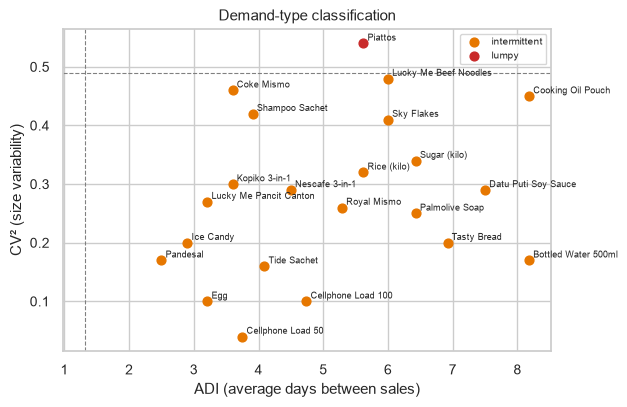

,ADI,CV2,Demand_type,Zero_sale_days_%,ABC,Suggested_model
Product,,,,,,
Pandesal,2.50,0.17,intermittent,60.0,A,Croston / moving average
Ice Candy,2.90,0.20,intermittent,66.0,A,Croston / moving average
Lucky Me Pancit Canton,3.21,0.27,intermittent,69.0,A,Croston / moving average
Egg,3.21,0.10,intermittent,69.0,A,Croston / moving average
Coke Mismo,3.60,0.46,intermittent,72.0,A,Croston / moving average
Kopiko 3-in-1,3.60,0.30,intermittent,72.0,A,Croston / moving average
Cellphone Load 50,3.75,0.04,intermittent,73.0,A,Croston / moving average
Shampoo Sachet,3.91,0.42,intermittent,74.0,A,Croston / moving average
Tide Sachet,4.09,0.16,intermittent,76.0,A,Croston / moving average


In [11]:
def classify(s):
    nz = s[s > 0]
    if len(nz) == 0: return np.nan, np.nan, 'no sales'
    adi = len(s) / len(nz)
    cv2 = (nz.std(ddof=0) / nz.mean()) ** 2 if len(nz) > 1 else 0.0
    if adi < 1.32: t = 'smooth' if cv2 < 0.49 else 'erratic'
    else:          t = 'intermittent' if cv2 < 0.49 else 'lumpy'
    return adi, cv2, t

SUGGEST = {'smooth': 'Holt-Winters / regression', 'erratic': 'Moving average / regression',
           'intermittent': 'Croston / moving average', 'lumpy': 'Croston + safety buffer', 'no sales': '-'}
dt = pd.DataFrame([(p, *classify(daily[p])) for p in daily], columns=['Product', 'ADI', 'CV2', 'Demand_type']).set_index('Product')
dt['Zero_sale_days_%'] = ((daily == 0).mean() * 100).round(0)
dt['ABC'] = prod['ABC']
dt['Suggested_model'] = dt.Demand_type.map(SUGGEST)
dt = dt.round({'ADI': 2, 'CV2': 2}).sort_values('ADI')
print(dt.Demand_type.value_counts().to_dict())
print('\nABC x demand type (number of products):')
display(pd.crosstab(dt.ABC, dt.Demand_type))

fig, ax = plt.subplots(figsize=(6.4, 4.2))
pal = {'smooth': '#2b8a3e', 'erratic': '#1f5fa8', 'intermittent': '#e67700', 'lumpy': '#c92a2a'}
for t, g in dt.groupby('Demand_type'):
    ax.scatter(g.ADI, g.CV2, s=40, c=pal.get(t, 'gray'), label=t)
for p, r in dt.iterrows():
    ax.annotate(p, (r.ADI, r.CV2), fontsize=6.5, xytext=(3, 2), textcoords='offset points')
ax.axvline(1.32, ls='--', c='gray', lw=.8); ax.axhline(0.49, ls='--', c='gray', lw=.8)
ax.set_xlabel('ADI (average days between sales)'); ax.set_ylabel('CV² (size variability)')
ax.set_title('Demand-type classification'); ax.legend(fontsize=7)
plt.tight_layout(); plt.savefig(OUT / 'fig_demand_types.png', dpi=170); plt.show()
dt

## 6. Time patterns

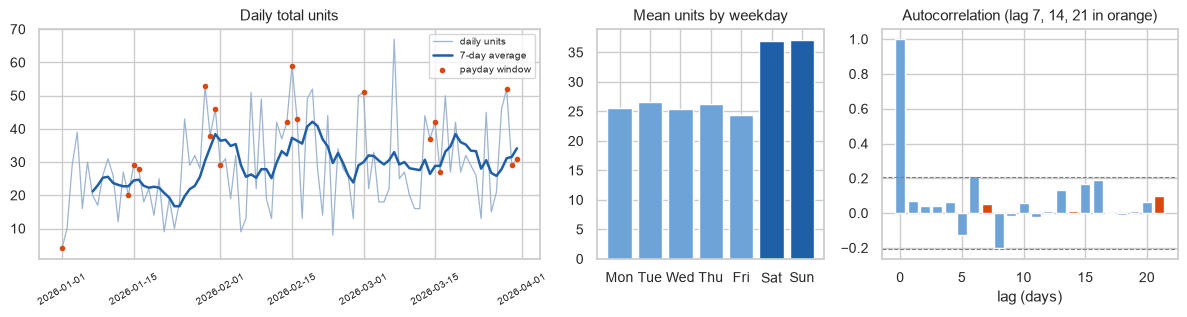

ACF at lag 7 = 0.05 (significance bound ±0.21)
STL weekly seasonal strength = 0.29 (0 = none, 1 = very strong; >0.4 supports seasonal_periods=7)


In [12]:
total = daily.sum(axis=1)
dow_names = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
dow_mean = total.groupby(total.index.dayofweek).mean().reindex(range(7))
nlags = min(21, N_DAYS // 2 - 1)
ac = acf(total, nlags=nlags); bound = 1.96 / np.sqrt(N_DAYS)

fig, axs = plt.subplots(1, 3, figsize=(12, 3.3), gridspec_kw={'width_ratios': [2.2, 1, 1.3]})
axs[0].plot(total.index, total, lw=.9, c='#9db4cf', label='daily units')
axs[0].plot(total.index, total.rolling(7).mean(), lw=1.8, c='#1f5fa8', label='7-day average')
pay_mask = total.index.day.isin(PAYDAY_DAYS)
axs[0].scatter(total.index[pay_mask], total[pay_mask], s=9, c='#d9480f', label='payday window', zorder=3)
axs[0].legend(fontsize=7); axs[0].set_title('Daily total units'); axs[0].tick_params(axis='x', labelsize=7, rotation=30)
axs[1].bar(dow_names, dow_mean, color=['#6ea3d8'] * 5 + ['#1f5fa8'] * 2); axs[1].set_title('Mean units by weekday')
axs[2].bar(range(len(ac)), ac, color=['#d9480f' if l % 7 == 0 and l else '#6ea3d8' for l in range(len(ac))])
axs[2].axhline(bound, ls='--', c='gray', lw=.8); axs[2].axhline(-bound, ls='--', c='gray', lw=.8)
axs[2].set_title('Autocorrelation (lag 7, 14, 21 in orange)'); axs[2].set_xlabel('lag (days)')
plt.tight_layout(); plt.savefig(OUT / 'fig_time_patterns.png', dpi=170); plt.show()

print(f'ACF at lag 7 = {ac[7]:.2f} (significance bound ±{bound:.2f})' if nlags >= 7 else 'Too few days for lag-7 ACF')
if N_DAYS >= 14:
    stl = STL(total, period=7, robust=True).fit()
    strength = max(0, 1 - stl.resid.var() / (stl.seasonal + stl.resid).var())
    print(f'STL weekly seasonal strength = {strength:.2f} (0 = none, 1 = very strong; >0.4 supports seasonal_periods=7)')

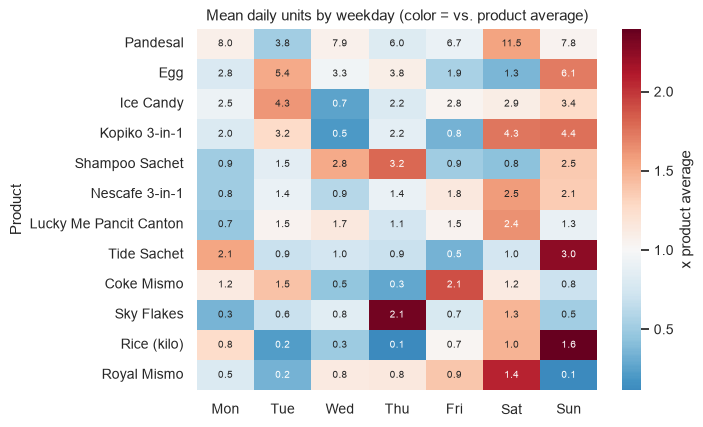

In [13]:
# Product x weekday heatmap (top 12 by units), normalized per product so patterns are comparable
top12 = prod.sort_values('Units', ascending=False).index[:12]
hm = daily[top12].groupby(daily.index.dayofweek).mean().T
hm.columns = dow_names
hm_norm = hm.div(hm.mean(axis=1), axis=0)
fig, ax = plt.subplots(figsize=(7.2, 4.4))
sns.heatmap(hm_norm, annot=hm.round(1), fmt='', cmap='RdBu_r', center=1, cbar_kws={'label': 'x product average'}, ax=ax, annot_kws={'size': 7})
ax.set_title('Mean daily units by weekday (color = vs. product average)')
plt.tight_layout(); plt.savefig(OUT / 'fig_weekday_heatmap.png', dpi=170); plt.show()

In [14]:
# Statistical checks (Mann-Whitney U, non-parametric). With 3-4 weeks of data, treat these as early signals.
def mw(a, b, label):
    if len(a) < 2 or len(b) < 2: return [label, len(a), len(b), np.nan, np.nan, np.nan, 'not enough days']
    u, p = stats.mannwhitneyu(a, b, alternative='two-sided')
    return [label, len(a), len(b), round(a.median(), 1), round(b.median(), 1),
            round((a.mean() / b.mean() - 1) * 100, 1), f'p = {p:.3f}' + (' (significant)' if p < 0.05 else '')]
tests = [mw(total[pay_mask], total[~pay_mask], 'Payday window vs. other days'),
         mw(total[total.index.dayofweek >= 5], total[total.index.dayofweek < 5], 'Weekend vs. weekday')]
if HAS['Is_Rainy']:
    rain = df.groupby('Date')['Is_Rainy'].max().reindex(days, fill_value=0).astype(bool)
    tests.append(mw(total[rain], total[~rain], 'Rainy vs. dry days'))
else:
    print('Rain test skipped: no Is_Rainy column (the partner store log should record it).')
display(pd.DataFrame(tests, columns=['Comparison', 'Days (group)', 'Days (other)', 'Median (group)', 'Median (other)', 'Mean diff %', 'Result']))

# Regression separates the payday effect from the weekday effect (a payday can fall on a weekend)
reg = pd.DataFrame({'units': total.values, 'dow': days.dayofweek, 'payday': pay_mask.astype(int)}, index=days)
formula = 'units ~ C(dow) + payday'
if HAS['Is_Rainy']:
    reg['rainy'] = rain.astype(int).values; formula += ' + rainy'
fit = smf.ols(formula, reg).fit()
ci = fit.conf_int()
eff = pd.DataFrame({'Effect (units/day)': fit.params, '95% CI low': ci[0], '95% CI high': ci[1], 'p-value': fit.pvalues}).round(3)
eff = eff.drop('Intercept').rename(index={f'C(dow)[T.{i}]': f'{dow_names[i]} vs. Mon' for i in range(1, 7)})
print(f'OLS: {formula}  (R² = {fit.rsquared:.2f}, n = {len(reg)} days)')
eff

Rain test skipped: no Is_Rainy column (the partner store log should record it).


,Comparison,Days (group),Days (other),Median (group),Median (other),Mean diff %,Result
0,Payday window vs. other days,18,72,37.5,26.0,35.6,p = 0.004 (significant)
1,Weekend vs. weekday,26,64,38.0,26.0,44.4,p = 0.001 (significant)


OLS: units ~ C(dow) + payday  (R² = 0.20, n = 90 days)


,Effect (units/day),95% CI low,95% CI high,p-value
Tue vs. Mon,2.213,-7.636,12.062,0.656
Wed vs. Mon,0.963,-9.082,11.009,0.849
Thu vs. Mon,0.692,-9.101,10.486,0.889
Fri vs. Mon,-0.624,-10.432,9.183,0.900
Sat vs. Mon,11.385,1.591,21.178,0.023
Sun vs. Mon,10.326,0.477,20.175,0.040
payday,7.882,1.095,14.670,0.023


In [15]:
# Time of day (needs a Time column, e.g. 07:45)
if HAS['Time']:
    hr = pd.to_datetime(df['Time'].astype(str), format='mixed').dt.hour
    df['Daypart'] = pd.cut(hr, [-1, 10, 14, 17, 24], labels=['Morning (<11)', 'Midday (11-14)', 'Afternoon (15-17)', 'Evening (18+)'])
    dp = df.pivot_table(index='Product', columns='Daypart', values='Base_Qty', aggfunc='sum', fill_value=0)
    dp = dp.loc[top12].div(dp.loc[top12].sum(axis=1), axis=0).mul(100).round(0)
    display(dp)
else:
    print('Time-of-day analysis skipped: no Time column.')

Time-of-day analysis skipped: no Time column.


## 7. Basket EDA before Apriori

90 DAY-LEVEL groups (no Trans_ID): NOT real customer baskets, code test only
Average distinct items per basket = 4.83 | single-item share = 0.0%


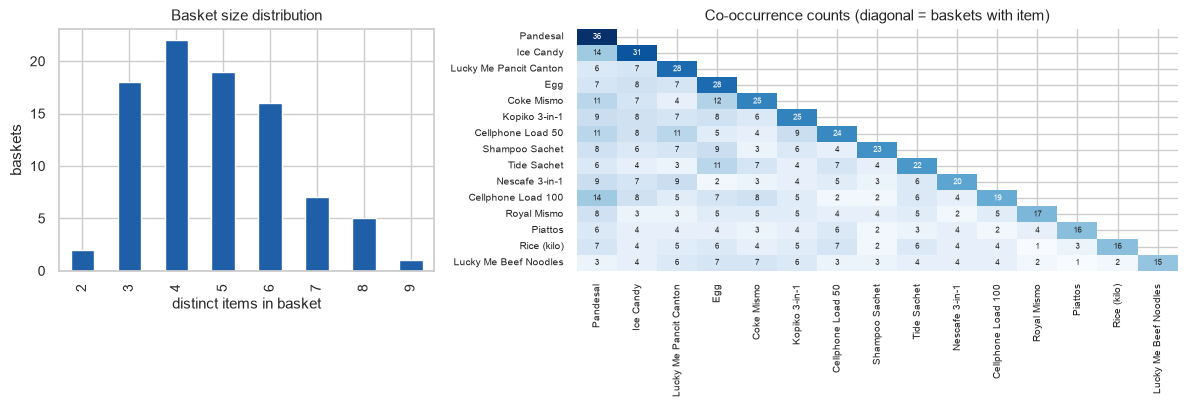

In [16]:
if HAS['Trans_ID']:
    baskets = df.groupby('Trans_ID')['Product'].apply(lambda s: sorted(set(s)))
    BASKET_KIND = 'transaction baskets'
else:
    baskets = df.groupby(df['Date'].dt.date)['Product'].apply(lambda s: sorted(set(s)))
    BASKET_KIND = 'DAY-LEVEL groups (no Trans_ID): NOT real customer baskets, code test only'
sizes = baskets.apply(len)
single_share = (sizes == 1).mean() * 100
print(f'{len(baskets)} {BASKET_KIND}')
print(f'Average distinct items per basket = {sizes.mean():.2f} | single-item share = {single_share:.1f}%')

onehot = pd.DataFrame([{i: True for i in b} for b in baskets]).fillna(False).astype(bool)
item_support = onehot.mean().sort_values(ascending=False)
top15 = item_support.index[:15]
co = onehot[top15].astype(int).T @ onehot[top15].astype(int)

fig, axs = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={'width_ratios': [1, 1.6]})
sizes.value_counts().sort_index().plot.bar(ax=axs[0], color='#1f5fa8')
axs[0].set_title('Basket size distribution'); axs[0].set_xlabel('distinct items in basket'); axs[0].set_ylabel('baskets')
mask = np.triu(np.ones_like(co, dtype=bool), k=1)
sns.heatmap(co, mask=mask, annot=True, fmt='d', cmap='Blues', ax=axs[1], annot_kws={'size': 6}, cbar=False)
axs[1].set_title('Co-occurrence counts (diagonal = baskets with item)'); axs[1].tick_params(labelsize=7)
plt.tight_layout(); plt.savefig(OUT / 'fig_baskets.png', dpi=170); plt.show()

In [17]:
# Pass 2 (multi-item baskets only) with a data-driven min_support:
# a pair must appear in at least 5 baskets, or 2% of multi-item baskets, whichever is larger.
multi = onehot[(sizes >= 2).values]
MIN_SUPPORT = max(5 / max(len(multi), 1), 0.02)
print(f'Multi-item baskets: {len(multi)} | suggested min_support = {MIN_SUPPORT:.3f}')
freq = apriori(multi, min_support=MIN_SUPPORT, use_colnames=True) if len(multi) else pd.DataFrame()
if len(freq) and (freq.itemsets.apply(len) > 1).any():
    try:
        rules = association_rules(freq, metric='lift', min_threshold=1.0)
    except TypeError:
        rules = association_rules(freq, len(multi), metric='lift', min_threshold=1.0)
    rules = rules[['antecedents', 'consequents', 'support', 'confidence', 'lift']].copy()
    rules['baskets'] = (rules.support * len(multi)).round().astype(int)
    n_all = len(rules)
    rules = rules[rules.baskets >= MIN_PAIR_BASKETS].copy()
    def fisher_p(a, c):   # one-sided: are A and C bought together more often than chance?
        A, Cc = multi[list(a)].all(axis=1), multi[list(c)].all(axis=1)
        return stats.fisher_exact([[(A & Cc).sum(), (A & ~Cc).sum()], [(~A & Cc).sum(), (~A & ~Cc).sum()]],
                                  alternative='greater')[1]
    rules['fisher_p'] = [fisher_p(a, c) for a, c in zip(rules.antecedents, rules.consequents)]
    rules['significant'] = rules.fisher_p < 0.05
    for c in ['antecedents', 'consequents']: rules[c] = rules[c].apply(lambda s: ', '.join(sorted(s)))
    rules = rules.sort_values(['significant', 'lift'], ascending=False).round(3)
    print(f'{n_all} rules with lift > 1 -> {len(rules)} seen in >= {MIN_PAIR_BASKETS} baskets -> '
          f'{int(rules.significant.sum())} significant (Fisher p < 0.05)')
    rules.to_csv(OUT / 'apriori_rules.csv', index=False)
    if not HAS['Trans_ID']: print('WARNING: day-level groups. These rules mean "sold on the same day", not "bought together".')
    display(rules.head(10))
else:
    rules = pd.DataFrame(); print('No frequent pairs at this support level.')

Multi-item baskets: 90 | suggested min_support = 0.056


158 rules with lift > 1 -> 158 seen in >= 5 baskets -> 34 significant (Fisher p < 0.05)


,antecedents,consequents,support,confidence,lift,baskets,fisher_p,significant
131,Cellphone Load 100,"Pandesal, Royal Mismo",0.056,0.263,2.961,5,0.009,True
130,"Pandesal, Royal Mismo",Cellphone Load 100,0.056,0.625,2.961,5,0.009,True
124,"Coke Mismo, Kopiko 3-in-1",Egg,0.056,0.833,2.679,5,0.010,True
125,Egg,"Coke Mismo, Kopiko 3-in-1",0.056,0.179,2.679,5,0.010,True
152,"Egg, Lucky Me Beef Noodles",Coke Mismo,0.056,0.714,2.571,5,0.016,True
157,Coke Mismo,"Egg, Lucky Me Beef Noodles",0.056,0.200,2.571,5,0.016,True
128,"Cellphone Load 100, Royal Mismo",Pandesal,0.056,1.000,2.500,5,0.009,True
154,"Coke Mismo, Egg",Lucky Me Beef Noodles,0.056,0.417,2.500,5,0.026,True
155,Lucky Me Beef Noodles,"Coke Mismo, Egg",0.056,0.333,2.500,5,0.026,True
133,Pandesal,"Cellphone Load 100, Royal Mismo",0.056,0.139,2.500,5,0.009,True


## 8. Stockouts and estimated lost demand

In [18]:
if HAS['Stockout_Flag']:
    so = (df.groupby(['Date', 'Product'])['Stockout_Flag'].max().unstack(fill_value=0)
            .reindex(index=days, columns=daily.columns, fill_value=0))
    SO_LABEL = 'recorded'
elif ADD_MOCK_STOCKOUTS:
    rng = np.random.default_rng(7)
    so = pd.DataFrame((rng.random(daily.shape) < 0.05).astype(int), index=days, columns=daily.columns)
    SO_LABEL = 'MOCK (random 5%, code test only)'
else:
    so = None
if so is not None:
    # Demand on a stockout day is censored: estimate it from the 7-day rolling MEAN of earlier in-stock days
    # (a median is 0 for items that sell only every few days, which would hide lost sales)
    base = daily.where(so == 0).rolling(7, min_periods=3).mean().shift(1)
    lost = (base - daily).clip(lower=0).where(so == 1).fillna(0)
    so_tab = pd.DataFrame({'Stockout_days': so.sum(), 'Est_lost_units': lost.sum().round(1)})
    so_tab['Est_lost_%_of_demand'] = (so_tab.Est_lost_units / (daily.sum() + so_tab.Est_lost_units) * 100).round(1)
    if HAS['UnitPrice']:
        so_tab['Est_lost_sales_PHP'] = (so_tab.Est_lost_units * df.groupby('Product').UnitPrice.median()).round(0)
    print('Stockout flags:', SO_LABEL)
    display(so_tab.sort_values('Est_lost_units', ascending=False).head(10))

# Forecasts use demand, not censored sales: on recorded stockout days, sales are raised to the rolling-mean estimate.
# Mock flags are never fed into the forecasts.
SO_FOR_MODELS = so is not None and SO_LABEL == 'recorded'
daily_fc = daily + lost if SO_FOR_MODELS else daily.copy()
print('Stockout correction for forecasting:', f'applied ({int((lost > 0).sum().sum())} product-days raised)'
      if SO_FOR_MODELS else 'not applied (no recorded Stockout_Flag)')

Stockout flags: MOCK (random 5%, code test only)


,Stockout_days,Est_lost_units,Est_lost_%_of_demand,Est_lost_sales_PHP
Product,,,,
Pandesal,4,27.4,4.0,82.0
Egg,4,10.0,3.1,90.0
Nescafe 3-in-1,8,9.1,6.1,82.0
Shampoo Sachet,3,8.7,5.1,70.0
Lucky Me Pancit Canton,6,7.5,5.4,112.0
Ice Candy,4,4.1,1.7,20.0
Kopiko 3-in-1,7,3.8,1.7,30.0
Rice (kilo),3,3.1,4.8,170.0
Coke Mismo,4,2.6,2.6,52.0


Stockout correction for forecasting: not applied (no recorded Stockout_Flag)


## 9. Week-over-week batch summary

In [19]:
wk = df.assign(Week=df['Date'].dt.to_period('W-SUN'))
agg = {'Days': ('Date', 'nunique'), 'Lines': ('Product', 'size'), 'Units': ('Base_Qty', 'sum')}
if HAS['UnitPrice']: agg['Sales'] = ('Sales', 'sum')
if HAS['Trans_ID']: agg['Transactions'] = ('Trans_ID', 'nunique')
weekly = wk.groupby('Week').agg(**agg)
weekly['Units_per_day'] = (weekly.Units / weekly.Days).round(1)
full = weekly.Days.eq(7) & weekly.Days.shift().eq(7)
weekly['Units_vs_prev_%'] = (weekly.Units.pct_change() * 100).round(1).where(full)
weekly['Top_3'] = wk.groupby('Week').apply(lambda g: ', '.join(g.groupby('Product').Base_Qty.sum().nlargest(3).index))
weekly['Check'] = np.where(weekly.Days < 7, 'partial week',
                    np.where(weekly['Units_vs_prev_%'].abs() > 30, 'big change: check log', 'ok'))
weekly

,Days,Lines,Units,Sales,Units_per_day,Units_vs_prev_%,Top_3,Check
Week,,,,,,,,
2025-12-29/2026-01-04,4,19,82,1243,20.5,NaN,"Nescafe 3-in-1, Egg, Tide Sachet",partial week
2026-01-05/2026-01-11,7,33,166,2349,23.7,NaN,"Pandesal, Ice Candy, Nescafe 3-in-1",ok
2026-01-12/2026-01-18,7,37,156,2089,22.3,-6.0,"Pandesal, Egg, Ice Candy",ok
2026-01-19/2026-01-25,7,33,138,1791,19.7,-11.5,"Egg, Ice Candy, Sky Flakes",ok
2026-01-26/2026-02-01,7,48,255,3490,36.4,84.8,"Pandesal, Egg, Kopiko 3-in-1",big change: check log
2026-02-02/2026-02-08,7,34,177,2464,25.3,-30.6,"Pandesal, Egg, Kopiko 3-in-1",big change: check log
2026-02-09/2026-02-15,7,45,261,2893,37.3,47.5,"Pandesal, Kopiko 3-in-1, Ice Candy",big change: check log
2026-02-16/2026-02-22,7,40,243,2635,34.7,-6.9,"Pandesal, Egg, Shampoo Sachet",ok
2026-02-23/2026-03-01,7,39,210,2202,30.0,-13.6,"Pandesal, Egg, Shampoo Sachet",ok


## 10. Rolling-origin forecast check
At each origin the models are re-fit **from scratch** on all earlier days (no shuffling, no future data). Two horizons are scored:
* **1 day ahead**, for model diagnostics.
* **Next 7 days total**, which is what the "Restock Soon" signal uses.

Metrics: **MAE** (units), **bias** (average forecast − actual; negative = under-forecasting, which causes stockouts) and **MASE** (MAE ÷ in-sample error of the same-day-last-week forecast; below 1 = better than naive, comparable across products). MAPE is not used because many product-days are zero. Croston uses the **SBA** bias correction.

If the log has a recorded `Stockout_Flag`, stockout days are first raised to the estimated demand from Section 8, so the models learn demand rather than sales cut short by an empty shelf. The linear regression also gets `rainy` and `stockout` dummies when those columns exist. For future days, rain is set to the past share of rainy days and the stockout dummy to 0 (item in stock).

In [20]:
days_ext = pd.date_range(days[0], periods=N_DAYS + 7, freq='D')          # +7 future days for the restock forecast
# Regression features: trend, weekday dummies, payday, plus rainy and stockout dummies when they are logged
X_base = np.column_stack([np.arange(len(days_ext)),
                          pd.get_dummies(days_ext.dayofweek, drop_first=True).astype(int).values,
                          days_ext.day.isin(PAYDAY_DAYS).astype(int)])
RAIN_COL = X_base.shape[1] if HAS['Is_Rainy'] else None
if RAIN_COL is not None:
    X_base = np.column_stack([X_base, np.r_[rain.astype(int).values, np.zeros(7)]])
SO_COL = X_base.shape[1] if SO_FOR_MODELS else None

def make_X(stock=None):
    return X_base if SO_COL is None else np.column_stack([X_base, np.r_[stock, np.zeros(7)]])
print('Regression features: trend, weekday, payday' + (', rainy' if RAIN_COL is not None else '')
      + (', stockout' if SO_COL is not None else ''))
MODELS = ['Naive (last week)', '7-day MA', 'Holt-Winters', 'Linear regression', 'Croston (SBA)']

def croston_sba(y, alpha=CROSTON_ALPHA):
    nz = np.flatnonzero(y > 0)
    if len(nz) == 0: return 0.0
    z, p, last = y[nz[0]], nz[0] + 1.0, nz[0]
    for i in nz[1:]:
        z += alpha * (y[i] - z); p += alpha * ((i - last) - p); last = i
    return (1 - alpha / 2) * z / p

def fc(model, tr, h, X=None):
    t, X = len(tr), X_base if X is None else X
    if model == MODELS[0]:   f = np.array([tr[t - 7 + (i % 7)] for i in range(h)])
    elif model == MODELS[1]: f = np.repeat(tr[-7:].mean(), h)
    elif model == MODELS[2]:
        try: f = ExponentialSmoothing(tr, trend=None, seasonal='add', seasonal_periods=7).fit().forecast(h)
        except Exception: f = np.repeat(tr[-7:].mean(), h)
    elif model == MODELS[3]:
        Xf = X[t:t + h].astype(float).copy()   # future days: rain unknown, item assumed in stock
        if RAIN_COL is not None: Xf[:, RAIN_COL] = X[:t, RAIN_COL].mean()
        if SO_COL is not None:   Xf[:, SO_COL] = 0
        f = LinearRegression().fit(X[:t], tr).predict(Xf)
    else:                    f = np.repeat(croston_sba(tr), h)
    return np.clip(np.asarray(f, dtype=float), 0, None)

def backtest(y, H, h, X=None):
    first = len(y) - H
    train = y[:first]   # MASE scale: in-sample error of the naive forecast for the same horizon
    scale = np.mean([abs(train[i:i + h].sum() - fc(MODELS[0], train[:i], h).sum()) for i in range(7, first - h + 1)])
    out = {}
    for m in MODELS:
        e = np.array([fc(m, y[:t], h, X).sum() - y[t:t + h].sum() for t in range(first, len(y) - h + 1)])
        out[m] = {'MAE': np.abs(e).mean(), 'Bias': e.mean(), 'MASE': np.abs(e).mean() / scale if scale else np.nan, 'errors': e}
    return out

H = min(HOLDOUT_DAYS, N_DAYS - 14)
series = {'TOTAL (all products)': daily_fc.sum(axis=1).values.astype(float)}
XS = {'TOTAL (all products)': make_X(so.mean(axis=1).values if SO_FOR_MODELS else None)}
for p in prod.sort_values('Units', ascending=False).index[:TOP_N]:
    series[p] = daily_fc[p].values.astype(float)
    XS[p] = make_X(so[p].values if SO_FOR_MODELS else None)
BT = {}
if H < 7:
    print(f'Only {N_DAYS} days: at least 21 days are needed for the 1-day test and 24 for the 7-day test.')
else:
    print(f'Test window: last {H} days ({days[-H].date()} to {days[-1].date()}); '
          f'{H - 6} weekly origins for the 7-day-total test')
    for k, y in series.items():
        BT[k] = {1: backtest(y, H, 1, XS[k]), 7: backtest(y, H, 7, XS[k]) if H >= 10 else None}
    res1 = pd.DataFrame({k: {m: v[1][m]['MAE'] for m in MODELS} for k, v in BT.items()}).T.round(2)
    res1['Best'] = res1.idxmin(axis=1)
    print('1-day-ahead MAE (units/day)'); display(res1)

Regression features: trend, weekday, payday
Test window: last 28 days (2026-03-04 to 2026-03-31); 22 weekly origins for the 7-day-total test


1-day-ahead MAE (units/day)


,Naive (last week),7-day MA,Holt-Winters,Linear regression,Croston (SBA),Best
TOTAL (all products),14.64,11.56,9.88,11.90,10.83,Holt-Winters
Pandesal,12.64,10.81,10.15,11.35,10.23,Holt-Winters
Egg,5.04,3.83,4.66,5.00,4.54,7-day MA
Ice Candy,5.14,4.19,4.10,4.53,4.32,Holt-Winters
Kopiko 3-in-1,4.71,4.68,3.96,4.42,4.01,Holt-Winters
Shampoo Sachet,3.39,2.52,3.20,4.01,3.14,7-day MA
Nescafe 3-in-1,3.25,2.94,3.03,2.40,2.51,Linear regression


In [21]:
if BT and all(v[7] for v in BT.values()):
    res7 = pd.DataFrame({k: {m: v[7][m]['MAE'] for m in MODELS} for k, v in BT.items()}).T.round(1)
    res7['Best'] = res7.idxmin(axis=1)
    res7['Bias'] = [round(BT[k][7][b]['Bias'], 1) for k, b in res7.Best.items()]
    res7['MASE'] = [round(BT[k][7][b]['MASE'], 2) for k, b in res7.Best.items()]
    res7['Demand type'] = [dt.Demand_type.get(k, 'aggregate') for k in res7.index]
    res7.to_csv(OUT / 'forecast_7day_mae.csv'); res1.to_csv(OUT / 'forecast_1day_mae.csv')
    print('Next-7-days-total MAE (units/week); Bias and MASE are for the best model')
    display(res7)
else:
    res7 = None; print('7-day-total test skipped: needs at least 24 days of log.')

Next-7-days-total MAE (units/week); Bias and MASE are for the best model


,Naive (last week),7-day MA,Holt-Winters,Linear regression,Croston (SBA),Best,Bias,MASE,Demand type
TOTAL (all products),35.3,35.3,26.6,34.8,27.2,Holt-Winters,-0.1,0.52,aggregate
Pandesal,29.0,29.0,28.4,21.9,27.1,Linear regression,-2.1,0.78,intermittent
Egg,13.6,13.6,14.4,20.4,14.5,Naive (last week),5.0,1.03,intermittent
Ice Candy,20.7,20.7,14.5,15.4,15.4,Holt-Winters,-2.7,1.27,intermittent
Kopiko 3-in-1,20.4,20.4,12.7,16.4,13.4,Holt-Winters,-4.3,0.97,intermittent
Shampoo Sachet,15.3,15.3,12.7,15.1,12.9,Holt-Winters,4.9,1.04,intermittent
Nescafe 3-in-1,14.7,14.7,11.3,11.4,8.8,Croston (SBA),-2.1,1.14,intermittent


## 11. Next-7-day restock suggestion (with an 80% range)
For each series, the model with the lowest 7-day-total MAE is re-fit on **all** days and forecasts the next 7 days. The 80% range is the forecast adjusted by that model's own backtest errors, so a model that tended to over-forecast gets a lower range. The suggested stock level is the top of the range, so it should cover the week about 9 times in 10.

In [22]:
if res7 is not None:
    rows = []
    for k, y in series.items():
        best = res7.loc[k, 'Best']; e = BT[k][7][best]['errors']
        point = fc(best, y, 7, XS[k]).sum()
        # range = forecast minus the model's own past errors (so a model that over-forecast gets a lower range)
        lo, hi = max(0, point - np.quantile(e, INTERVAL[1])), max(0, point - np.quantile(e, INTERVAL[0]))
        rows.append([k, best, round(point, 1), round(e.mean(), 1), f'{lo:.0f} to {hi:.0f}', math.ceil(hi), len(e)])
    restock = pd.DataFrame(rows, columns=['Series', 'Model', 'Forecast next 7 days', 'Past bias', '80% range',
                                          'Suggested stock (units)', 'Backtest weeks'])
    if STOCK:   # stock counts from the app: flag products whose forecast is above stock on hand
        restock['Stock on hand'] = restock['Series'].map(STOCK)
        restock['Restock soon'] = [None if pd.isna(s) else bool(f > s) for f, s in zip(restock['Forecast next 7 days'], restock['Stock on hand'])]
    if restock['Backtest weeks'].min() < 8:
        print('Note: fewer than 8 backtest weeks, so the 80% range is rough. It improves as more weeks are logged.')
    restock.to_csv(OUT / 'restock_next7.csv', index=False)
    print(f'Forecast for {days_ext[N_DAYS].date()} to {days_ext[-1].date()}. Compare with stock on hand for "Restock Soon".')
    display(restock)

Forecast for 2026-04-01 to 2026-04-07. Compare with stock on hand for "Restock Soon".


,Series,Model,Forecast next 7 days,Past bias,80% range,Suggested stock (units),Backtest weeks
0,TOTAL (all products),Holt-Winters,221.1,-0.1,181 to 259,259,22
1,Pandesal,Linear regression,78.9,-2.1,43 to 116,117,22
2,Egg,Naive (last week),25.0,5.0,8 to 42,43,22
3,Ice Candy,Holt-Winters,18.7,-2.7,0 to 47,48,22
4,Kopiko 3-in-1,Holt-Winters,17.3,-4.3,7 to 49,49,22
5,Shampoo Sachet,Holt-Winters,8.4,4.9,0 to 20,21,22
6,Nescafe 3-in-1,Croston (SBA),10.2,-2.1,1 to 24,24,22


## 12. Automatic summary and saved outputs

In [23]:
lines = [f'Dataset: {DATASET_LABEL}',
         f"Names: {len(uniq)} raw -> {df.Product.nunique()} standard ({mapping.Method.value_counts().to_dict()}).",
         f"{qc['Rows']} rows, {N_DAYS} days, {df.Product.nunique()} products; {qc['Missing values (all columns)']} missing values; "
         f"{qc['Exact duplicate rows (extra copies)']} duplicate rows ({'removed' if HAS['Trans_ID'] else 'flagged'}).",
         f"{len(outliers)} unusually high product-days to check; {len(CLOSED)} closed and {len(UNLOGGED)} unlogged days.",
         f"ABC: {prod.ABC.value_counts().to_dict()}; top 20% of items = {prod[key].head(top20).sum() / prod[key].sum() * 100:.0f}% of {key.lower()}.",
         f'Demand types: {dt.Demand_type.value_counts().to_dict()}.',
         f"Regression: payday {eff.loc['payday', 'Effect (units/day)']:+.1f} units/day (p = {eff.loc['payday', 'p-value']:.3f}), "
         f"Sat {eff.loc['Sat vs. Mon', 'Effect (units/day)']:+.1f}, Sun {eff.loc['Sun vs. Mon', 'Effect (units/day)']:+.1f} vs. Mon.",
         f"Baskets: {BASKET_KIND}; single-item share {single_share:.1f}%; {len(rules)} rules kept, "
         f"{int(rules.significant.sum()) if len(rules) else 0} significant."]
if res7 is not None:
    lines.append('Best 7-day model: ' + '; '.join(f'{k}: {r.Best} (MASE {r.MASE})' for k, r in res7.iterrows()) + '.')
summary = '\n'.join('- ' + l for l in lines)
(OUT / 'eda_summary.txt').write_text(summary, encoding='utf-8')
prod.to_csv(OUT / 'abc_analysis.csv'); dt.to_csv(OUT / 'demand_types.csv'); weekly.to_csv(OUT / 'weekly_summary.csv')
print(summary); print('\nSaved to', OUT.resolve())

- Dataset: Aling Nena Q1 2026 (online PH proxy, code testing only)
- Names: 22 raw -> 22 standard ({'exact': 22}).
- 494 rows, 90 days, 22 products; 0 missing values; 5 duplicate rows (flagged).
- 18 unusually high product-days to check; 0 closed and 0 unlogged days.
- ABC: {'A': 14, 'B': 5, 'C': 3}; top 20% of items = 33% of sales.
- Demand types: {'intermittent': 21, 'lumpy': 1}.
- Regression: payday +7.9 units/day (p = 0.023), Sat +11.4, Sun +10.3 vs. Mon.
- Baskets: DAY-LEVEL groups (no Trans_ID): NOT real customer baskets, code test only; single-item share 0.0%; 158 rules kept, 34 significant.
- Best 7-day model: TOTAL (all products): Holt-Winters (MASE 0.52); Pandesal: Linear regression (MASE 0.78); Egg: Naive (last week) (MASE 1.03); Ice Candy: Holt-Winters (MASE 1.27); Kopiko 3-in-1: Holt-Winters (MASE 0.97); Shampoo Sachet: Holt-Winters (MASE 1.04); Nescafe 3-in-1: Croston (SBA) (MASE 1.14).

Saved to D:\cjds0\1 CODES\Merkado\MerkaDo_EDA\outputs


## How to run this on the partner store log (Week 3 onward)
1. Save the encoded log as CSV, with **one row per item line** and at least `Date, Product, Qty`. Add `Trans_ID`, `Time`, `UnitPrice`, `UnitCost`, `PaymentType`, `Stockout_Flag`, `Is_Rainy` and `Pack_Multiplier` if recorded.
2. Set `DATA_PATH` and `DATASET_LABEL` in Section 0. Add any differently named headers to `COLUMN_MAP`, and set `ADD_MOCK_STOCKOUTS = False`. Fill `ALIASES` and `PACK_TABLE` from the store's product list.
3. Each week, append the new rows to the same CSV and *Run All*. The models are re-fit from scratch on all days so far.
4. Use Sections 1b, 2 and 9 to fix logging problems (unmatched names, unlogged days, big weekly changes) before reading Sections 4–11. Report only results from the store log, not from the proxy data.